In [1]:
# 0. 설정 및 라이브러리
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import StandardScaler

from pykrx import stock

plt.rc('font', family='NanumGothic')
plt.rcParams['axes.unicode_minus'] = False
print('✅ LSTM 예측 환경 준비 완료')



✅ LSTM 예측 환경 준비 완료


In [2]:
# 1. 종목 데이터 로딩 함수 (KRX)
from typing import Optional

def load_krx_daily(symbol: str, start: str = '2000-01-01', end: Optional[str] = None) -> pd.DataFrame:
    if end is None:
        end = datetime.now().strftime('%Y-%m-%d')
    df = stock.get_market_ohlcv_by_date(start.replace('-', ''), end.replace('-', ''), symbol)
    df = df.rename(columns={'종가': 'Close', '거래량': 'Volume'})
    df = df[['Close', 'Volume']]
    df.index = pd.to_datetime(df.index)
    df = df.sort_index()
    return df

# 주간 집계 및 타깃 (weekly_return) 생성
def to_weekly_with_target(daily: pd.DataFrame) -> pd.DataFrame:
    weekly = pd.DataFrame()
    weekly['Close'] = daily['Close'].resample('W-FRI').last()
    weekly['Volume'] = daily['Volume'].resample('W-FRI').sum()
    weekly['weekly_return'] = weekly['Close'].pct_change()
    weekly = weekly.dropna()
    return weekly

print('✅ 데이터 로딩 함수 준비 완료')



✅ 데이터 로딩 함수 준비 완료


In [3]:
# 2. 시퀀스 생성 및 데이터 분할
SEQ_LEN = 12  # 12주 히스토리로 다음 주 수익률 예측

# 입력 피처 스케일링 및 시퀀스 변환
def build_sequences(weekly_df: pd.DataFrame, seq_len: int = SEQ_LEN):
    features = weekly_df[['Close', 'Volume']].values
    target = weekly_df['weekly_return'].shift(-1).values  # 다음 주 수익률 예측
    valid_mask = ~np.isnan(target)
    features = features[valid_mask]
    target = target[valid_mask]

    scaler = StandardScaler()
    features_scaled = scaler.fit_transform(features)

    X_list, y_list, dates = [], [], []
    dates_src = weekly_df.index[valid_mask]

    for i in range(seq_len, len(features_scaled)):
        X_list.append(features_scaled[i-seq_len:i])
        y_list.append(target[i])
        dates.append(dates_src[i])

    X = np.array(X_list)
    y = np.array(y_list)
    dates = np.array(dates)
    return X, y, dates, scaler

# 시계열 분할 (최근 15% 검증)
def time_split(X, y, dates, valid_ratio=0.15):
    n = len(X)
    split = int(n * (1 - valid_ratio))
    return (X[:split], y[:split], dates[:split]), (X[split:], y[split:], dates[split:])

print('✅ 시퀀스/분할 함수 준비 완료')



✅ 시퀀스/분할 함수 준비 완료


In [5]:
# 3. 학습/평가 및 플롯, 이번 주 예측

def train_and_forecast(symbol: str = '092220', start: str = '2000-01-01'):
    # 1) 데이터 로딩 및 주간 집계
    daily = load_krx_daily(symbol, start=start)
    weekly = to_weekly_with_target(daily)

    # 2) 시퀀스 생성 및 분할
    X, y, dates, scaler = build_sequences(weekly)
    (X_tr, y_tr, d_tr), (X_va, y_va, d_va) = time_split(X, y, dates, valid_ratio=0.15)

    # 3) 모델 정의
    tf.keras.backend.clear_session()
    model = Sequential([
        LSTM(64, input_shape=(X.shape[1], X.shape[2]), return_sequences=True),
        Dropout(0.2),
        LSTM(32),
        Dropout(0.2),
        Dense(1)
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), loss='mse')

    # 4) 학습
    es = EarlyStopping(monitor='val_loss', patience=10, mode='min', restore_best_weights=True)
    history = model.fit(
        X_tr, y_tr,
        validation_data=(X_va, y_va),
        epochs=200,
        batch_size=64,
        callbacks=[es],
        verbose=0
    )

    # 5) 평가 및 예측
    va_pred = model.predict(X_va).ravel()

    # 6) 성과 요약
    from sklearn.metrics import r2_score, mean_absolute_error
    r2 = r2_score(y_va, va_pred)
    mae = mean_absolute_error(y_va, va_pred)
    print(f"Validation R2: {r2:.4f}, MAE: {mae:.4f}")

    # 7) 플롯: 실제 vs 예측
    plt.figure(figsize=(12, 5))
    plt.plot(d_va, y_va * 100, label='Actual (%)', linewidth=2)
    plt.plot(d_va, va_pred * 100, label='Predicted (%)', linewidth=2)
    plt.title(f'{symbol} 주간 수익률 예측 (검증 구간)')
    plt.xlabel('Date')
    plt.ylabel('Weekly Return (%)')
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # 8) 이번 주 예측: 마지막 시퀀스로 다음 주 수익률 예측
    last_seq = X[-1:]
    next_week_pred = float(model.predict(last_seq).ravel()[0])
    print(f"📈 {symbol} 이번 주 예상 수익률: {next_week_pred*100:.2f}%")

    # 9) 최근 구간 시각화
    recent_n = min(40, len(dates))
    plt.figure(figsize=(12, 5))
    plt.plot(dates[-recent_n:], weekly['weekly_return'].iloc[-recent_n:] * 100, label='Actual (%)', linewidth=2)
    plt.axhline(0, color='gray', linewidth=1, linestyle='--')
    plt.title(f'{symbol} 최근 주간 수익률 (최근 {recent_n}주) 및 이번 주 예측: {next_week_pred*100:.2f}%')
    plt.xlabel('Date')
    plt.ylabel('Weekly Return (%)')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    return {
        'symbol': symbol,
        'validation_r2': r2,
        'validation_mae': mae,
        'predicted_weekly_return': next_week_pred,
        'weekly_df': weekly,
    }

print('✅ 학습/예측 함수 준비 완료. 예: train_and_forecast("005930") 실행')



✅ 학습/예측 함수 준비 완료. 예: train_and_forecast("005930") 실행


3/3 [==============================] - 1s 9ms/step
Validation R2: 0.0123, MAE: 0.0382


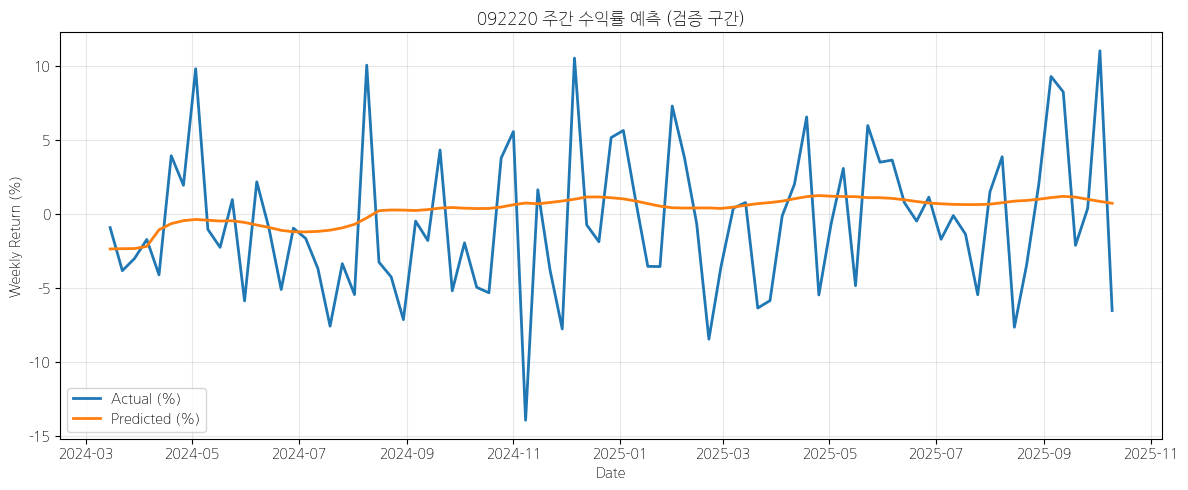

1/1 [==============================] - 0s 31ms/step
📈 092220 이번 주 예상 수익률: 0.71%


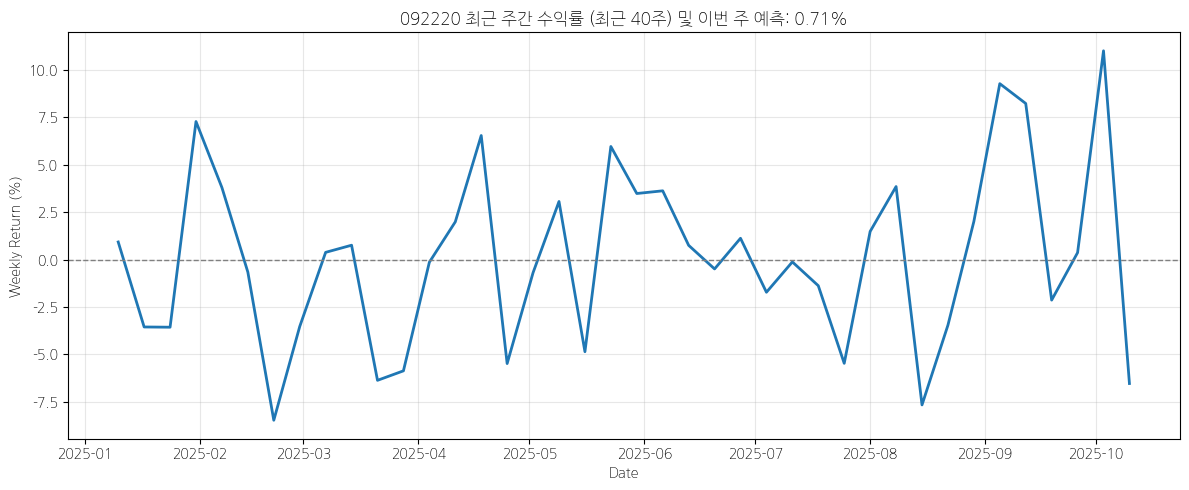

{'symbol': '092220',
 'validation_r2': 0.01226622107716957,
 'validation_mae': 0.03816926703659262,
 'predicted_weekly_return': 0.0070611461997032166,
 'weekly_df':              Close    Volume  weekly_return
 날짜                                         
 2015-01-09   964.0  15504748      -0.024291
 2015-01-16   988.0  10266001       0.024896
 2015-01-23   980.0   5770282      -0.008097
 2015-01-30  1000.0   6229060       0.020408
 2015-02-06  1143.0  19699128       0.143000
 ...            ...       ...            ...
 2025-09-19   841.0   6529370       0.082368
 2025-09-26   823.0   6732969      -0.021403
 2025-10-03   826.0   3024465       0.003645
 2025-10-10   917.0   7961056       0.110169
 2025-10-17   857.0   8136993      -0.065431
 
 [562 rows x 3 columns]}

In [6]:
train_and_forecast("092220", "2015-01-01")